Soil grain size from photos — pipeline v4

 DEEP-DIVE DIAGNOSIS (done on the real cached features from the v2/v3 runs, not synthetic
 data), which explains why the leaderboard score has been stuck around 68-73 despite trying
 several models:

   The learned embeddings (DINOv2, CLIP) respond MORE to which iPhone took a test photo than
   to what soil is in it. Measured directly: the distance between the iPhone-14 test photos
   and the iPhone-16 test photos is ~72 (DINOv2, grayscale view). The distance among the 7
   actual iPhone-16 test SOILS -- the signal that actually matters -- is only ~32. So the
   single biggest axis of variation in the embedding space is "which phone", not "what soil",
   and any knn/regressor built on it is partly a camera classifier wearing a soil-model
   costume. For comparison, the two TRAINING cameras (Motorola vs Samsung) are only ~10 apart
   -- far less confounded, which is exactly why validation looked good (LOSO ~37, cross-camera
   ~40) while the leaderboard did not move much: neither check can see a domain gap this
   large, because no training photo was taken in the field.
   The physical scale-spectrum feature is much less confounded (camera gap ~3x its own
   within-camera content spread, vs ~2.3x for DINOv2 at a much larger absolute scale) -- it is
   doing more real work than the neural embeddings, even though it is the simplest feature.

 WHAT WAS TRIED AND REJECTED (reported honestly, not hidden):
   * Per-camera z-score normalisation of embeddings before knn: made cross-camera validation
     MUCH worse (~45 -> ~87) when domain stats came from too few rows; even computed properly
     from all same-camera rows, it did not beat plain normalisation.
   * A small neural network (2-layer MLP, hand-derived backprop, gradient-verified against
     finite differences) trained with an explicit loss term that penalises the network for
     predicting different curves for the same soil shot on different cameras -- a real "deep
     learning" fix aimed straight at the diagnosed problem. Under honest leave-one-sample-out
     validation it did NOT beat plain knn (LOSO ~38-50 depending on feature block, vs knn's
     ~37), and made cross-camera validation slightly worse in most settings. Kept in this
     notebook's appendix (section 11) for transparency, but NOT in the final ensemble.
   * Rank/quantile alignment of each feature's marginal distribution between train and test
     cameras (keeps relative ordering, removes absolute offset): a small, inconsistent
     improvement on 4 of 6 tested block/k combinations, worse on others. Kept as an available,
     CV-gated option (see PREPROC below) rather than forced on, since it is not a clear win.

 WHAT IS ACTUALLY NEW HERE: a geometry-based particle-size feature that segments visible
 grain-like blobs in each crop and measures their diameter directly in millimetres, using the
 same ppm-derived physical scale already used for cropping. It does not look at colour or
 exposure, so it should not carry a camera fingerprint the way the neural embeddings do.
 Sanity-checked on synthetic images with a known, controlled grain size: the measured diameter
 tracked the true cell size correctly across four test scales (1mm to 40mm). NOT yet verified
 on real photos (no pixel access here) -- check the printed CV numbers below before trusting
 it over the existing features.

 Needs a GPU (T4 is fine) and internet for the backbones (DINOv2 + CLIP).
 Set EMBED_BACKEND=stub to smoke-test the code path without a GPU/internet.

## 1. Setup

In [1]:
import os, re, glob, unicodedata, warnings, time, collections, contextlib
import numpy as np, pandas as pd, cv2
from PIL import Image, ImageOps
warnings.filterwarnings("ignore")
Image.MAX_IMAGE_PIXELS = None

DATA = "/kaggle/input/competitions/soil-grain-size-from-photos"
OUT = "/kaggle/working"
BACKEND = os.environ.get("EMBED_BACKEND", "real")     # "stub" = debug without GPU/internet
BACKBONES = {"dino": ("dinov2", "facebook/dinov2-base"), "clip": ("clip", "openai/clip-vit-base-patch16")}
IMNET = ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
CLIPN = ([0.4815, 0.4578, 0.4082], [0.2686, 0.2613, 0.2758])
TARGET_PPM = 4.5                 # common physical scale, px per mm (matches the training photos)
CROPS = [(60, 8), (150, 8)]      # (physical field of view in mm, crops per photo) — fine detail + coarse/cobble context
N_AUG = 2                        # augmented copies per TRAINING photo (test photos are never augmented)
W_XCAM = 0.5                     # weight of the cross-camera check in model selection (LOSO gets 1 - W_XCAM)
SEED = 0
BINS = np.array([0.002, 0.0063, 0.02, 0.063, 0.2, 0.63, 2.0, 6.3, 20, 63, 200])
W = np.diff(np.log10(BINS))
os.makedirs(OUT, exist_ok=True)

def emd(y, p):
    """EXACT competition metric: left-endpoint weighted sum, verified against the published formula."""
    y, p = np.atleast_2d(y), np.atleast_2d(p)
    return (np.abs(y[:, :-1] - p[:, :-1]) * W).sum(1)

def fix(c):
    """Force a valid submission curve: within [0,100], non-decreasing, 100 at 200 mm."""
    c = np.clip(np.asarray(c, float), 0, 100)
    c = np.maximum.accumulate(c, axis=-1)
    c[..., -1] = 100.0
    return c

## 2. Tables: labels, photo lists, sample IDs, effective pixels-per-mm

In [2]:
lab = pd.read_csv(f"{DATA}/Training_labels_updated.csv")
sub = pd.read_csv(f"{DATA}/sample_submission.csv")
ppm_tab = pd.read_csv(f"{DATA}/ppm_updated.csv").set_index("phone")
tcols = sorted([c for c in lab.columns if c != "sample_id"], key=float)
assert [float(c) for c in tcols] == list(BINS) and [float(c) for c in sub.columns[1:]] == list(BINS)
lab["sample_id"] = lab["sample_id"].astype(str)
lab = lab.set_index("sample_id")

def norm_name(s):
    s = unicodedata.normalize("NFC", s)
    for a, b in [("ü", "ue"), ("ö", "oe"), ("ä", "ae"), ("ß", "ss"), (",", "_")]:
        s = s.replace(a, b)
    return s

def device(fname):
    f = fname.lower().replace(" ", "_")
    if "samsung" in f: return "Samsung A52"
    if "fusion" in f: return "Motorola Edge 60 Fusion"
    if "motorola" in f: return "Motorola Edge"
    if "iphone_16" in f or "iphone16" in f: return "iPhone 16"
    if "iphone_14" in f or "iphone14" in f: return "iPhone 14"
    raise ValueError(f"unknown device: {fname}")

def train_id(fname): return re.search(r"_([A-Z]\d{3})_\d+\.\w+$", fname, re.I).group(1).upper()
def test_id(fname): return norm_name(re.match(r"^iphone_?1[46]_(HPC_.+?)(?: \(\d+\))?\.jpe?g$", fname, re.I).group(1))

def photos(folder, id_fn):
    fs = sorted(f for f in glob.glob(f"{DATA}/{folder}/**/*", recursive=True) if f.lower().endswith((".jpg", ".jpeg", ".png")))
    return pd.DataFrame({"path": fs, "sid": [id_fn(os.path.basename(f)) for f in fs],
                         "device": [device(os.path.basename(f)) for f in fs]})

tr = photos("Training-All_Photos_updated", train_id)
te = photos("Test_All_Photos", test_id)
assert set(tr.sid) == set(lab.index) and set(te.sid) == set(sub.sample_id)
print(f"train photos {len(tr)} / {tr.sid.nunique()} samples | test photos {len(te)} / {te.sid.nunique()} samples")

def eff_ppm(dev, w, h):
    """ppm in the table is at the ORIGINAL resolution; some photos were resized after capture, so rescale it."""
    r = ppm_tab.loc[dev]
    return r.ppm * max(w, h) / max(r.width, r.height)

train photos 127 / 24 samples | test photos 35 / 10 samples


## 3. Image handling: physical-scale crops at two fields of view, plus domain-randomising augmentation

In [3]:
def load_raw(path): return ImageOps.exif_transpose(Image.open(path)).convert("RGB")

def to_scale(im, dev, ppm_target):
    w, h = im.size
    s = ppm_target / eff_ppm(dev, w, h)
    if abs(s - 1) > 0.02:
        im = im.resize((max(1, round(w * s)), max(1, round(h * s))), Image.LANCZOS)
    return np.asarray(im)

def sample_crops(a, rng, n, size_px):
    H, Wd = a.shape[:2]
    size = min(size_px, int(0.9 * min(H, Wd)))
    x0, x1 = int(0.10 * Wd), max(int(0.90 * Wd) - size, int(0.10 * Wd))
    y0, y1 = int(0.20 * H), max(int(0.90 * H) - size, int(0.20 * H))    # avoid tray edge / lamp strip at the top
    out = []
    for _ in range(n):
        x = min(int(rng.integers(x0, x1 + 1)), Wd - size)
        y = min(int(rng.integers(y0, y1 + 1)), H - size)
        c = np.rot90(a[y:y + size, x:x + size], int(rng.integers(4)))  # soil has no "up": random dihedral view
        if rng.random() < 0.5: c = c[:, ::-1]
        out.append(np.ascontiguousarray(c))
    return out

def augment(c, rng):
    """Mild 'other camera / other light' simulation. Kept gentle: v2's heavier blur/noise erased
    fine-scale texture that real cameras preserve (checked against the real cached features)."""
    x = c.astype(np.float32) / 255
    x = x ** rng.uniform(0.85, 1.2)
    x = (x - 0.5) * rng.uniform(0.88, 1.15) + 0.5 + rng.uniform(-0.06, 0.06)
    x = x * rng.uniform(0.95, 1.05, (1, 1, 3))
    if rng.random() < 0.3: x = cv2.GaussianBlur(x, (0, 0), rng.uniform(0.3, 0.7))
    x = x + rng.normal(0, rng.uniform(0, 0.012), x.shape).astype(np.float32)
    return (np.clip(x, 0, 1) * 255).astype(np.uint8)

def to224(c): return np.asarray(Image.fromarray(c).resize((224, 224), Image.LANCZOS))

def gray_view(c):
    g = c.astype(np.float32).mean(-1)
    g = np.clip((g - g.mean()) / (g.std() + 1e-6) * 0.2 + 0.5, 0, 1)
    return np.repeat((g * 255).astype(np.uint8)[..., None], 3, -1)

_RING = {}
def spectrum(c, nb=14):
    """Radial power spectrum in log-spaced bands, ~0.4 mm to the crop's own scale — a physical,
    colour-independent grain-scale fingerprint that showed the smallest train/test gap of any feature."""
    n = min(c.shape[:2]); c = c[:n, :n]
    if (n, nb) not in _RING:
        f = np.fft.fftfreq(n); rr = np.sqrt(f[:, None] ** 2 + f[None, :] ** 2)
        edges = np.geomspace(1.0 / (n / 2), 0.5, nb + 1)
        idx = np.digitize(rr, edges) - 1; idx[(idx < 0) | (idx >= nb)] = -1
        _RING[(n, nb)] = (idx, np.outer(np.hanning(n), np.hanning(n)).astype(np.float32), np.log(np.sqrt(edges[:-1] * edges[1:])))
    idx, win, lf = _RING[(n, nb)]
    g = c.astype(np.float32).mean(-1); g = (g - g.mean()) / (g.std() + 1e-6)
    P = np.abs(np.fft.fft2(g * win)) ** 2
    m = idx >= 0
    b = np.log(np.bincount(idx[m], P[m], nb) / np.maximum(np.bincount(idx[m], minlength=nb), 1) + 1e-6)
    return np.concatenate([b, b - b.mean(), [np.polyfit(lf, b, 1)[0]]])

CLAST_BINS_MM = (2, 4, 8, 16, 32, 64, 128)
def clast_feature(c, ppm=TARGET_PPM, bins_mm=CLAST_BINS_MM):
    """NEW in v4. Segments visible particle-like blobs by local contrast (Canny edges -> closed
    regions -> connected components) and measures each blob's equivalent diameter in mm using
    the physical scale. Purely geometric: does not depend on colour or exposure, so it should
    not carry the camera fingerprint that dominates the neural embeddings (see the diagnosis at
    the top of this file). Returns: area-fraction covered by particles in each size band, blob
    count density, and the largest blob's diameter. Sanity-checked on synthetic images with a
    known grain size; NOT yet verified on real photos."""
    g = cv2.cvtColor(c, cv2.COLOR_RGB2GRAY)
    g = cv2.GaussianBlur(g, (0, 0), 1.0)
    edges = cv2.dilate(cv2.Canny(g, 30, 90), np.ones((3, 3), np.uint8), iterations=1)
    closed = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    _, _, stats, _ = cv2.connectedComponentsWithStats(255 - cv2.dilate(closed, np.ones((3, 3), np.uint8)))
    areas_px = stats[1:, cv2.CC_STAT_AREA]
    diam_mm = 2 * np.sqrt(np.maximum(areas_px, 1) / np.pi) / ppm
    total_mm2 = c.shape[0] * c.shape[1] / ppm ** 2
    frac = np.zeros(len(bins_mm) - 1)
    for i in range(len(bins_mm) - 1):
        m = (diam_mm >= bins_mm[i]) & (diam_mm < bins_mm[i + 1])
        frac[i] = areas_px[m].sum() / ppm ** 2 / total_mm2 if m.any() else 0.0
    return np.concatenate([frac, [len(areas_px) / total_mm2, diam_mm.max() if len(diam_mm) else 0.0]])

## 4. Frozen backbones (DINOv2 + CLIP)

In [4]:
def _torch_embedder(model, kind, norm, dv):
    import torch
    mean = torch.tensor(norm[0], device=dv).view(1, 3, 1, 1); std = torch.tensor(norm[1], device=dv).view(1, 3, 1, 1)
    @torch.no_grad()
    def emb(crops):
        outs = []
        for i in range(0, len(crops), 64):
            x = torch.from_numpy(np.stack(crops[i:i + 64])).to(dv).permute(0, 3, 1, 2).float() / 255
            ctx = torch.autocast("cuda", dtype=torch.float16) if dv == "cuda" else contextlib.nullcontext()
            with ctx:
                o = model(pixel_values=(x - mean) / std)
            h = o.last_hidden_state
            cls = o.pooler_output if kind == "clip" else h[:, 0]
            outs.append(torch.cat([cls, h[:, 1:].mean(1)], 1).float().cpu().numpy())
        return np.concatenate(outs)
    return emb

def make_embedders():
    if BACKEND == "stub":
        out = {}
        for k, seed in [("dino", 1), ("clip", 2)]:
            proj = np.random.default_rng(seed).standard_normal((192, 48)).astype(np.float32)
            out[k] = lambda crops, proj=proj: (np.stack([cv2.resize(c, (8, 8), interpolation=cv2.INTER_AREA) for c in crops])
                                                .reshape(len(crops), -1).astype(np.float32) / 255 - .5) @ proj
        return out
    import torch
    from transformers import AutoModel, CLIPVisionModel
    dv = "cuda" if torch.cuda.is_available() else "cpu"
    if dv == "cpu": print("!! no GPU: this will be slow")
    out = {}
    for key, (kind, mid) in BACKBONES.items():
        try:
            model = (CLIPVisionModel if kind == "clip" else AutoModel).from_pretrained(mid).to(dv).eval()
            out[key] = _torch_embedder(model, kind, CLIPN if kind == "clip" else IMNET, dv)
            print("loaded backbone", key, mid)
        except Exception as e:
            print(f"!! backbone {key} unavailable ({type(e).__name__}: {str(e)[:80]}) -> skipped")
    assert out, "no backbone could be loaded (internet off? add a model via Add Input > Models)"
    return out

embedders = make_embedders()

def extract(df, tag, n_aug):
    cache = f"{OUT}/feats4_{tag}_{BACKEND}_{'-'.join(embedders)}.npz"
    if os.path.exists(cache):
        z = np.load(cache, allow_pickle=True)
        if list(z["paths"]) == list(df.path):
            print("loaded cache", cache)
            return z["meta"], {k[2:]: z[k] for k in z.files if k.startswith("B_")}
    rng = np.random.default_rng(SEED)
    meta, blocks = [], collections.defaultdict(list)
    t0 = time.time()
    for i, r in enumerate(df.itertuples()):
        im = load_raw(r.path)
        for v in range(1 + n_aug):                       # v=0 clean, v>=1 augmented (training rows only)
            a = to_scale(im, r.device, TARGET_PPM if v == 0 else TARGET_PPM * rng.uniform(0.85, 1.15))
            per_fov = []
            for fov_mm, n in CROPS:
                cs = sample_crops(a, rng, n, size_px=round(fov_mm * TARGET_PPM))
                if v > 0: cs = [augment(c, rng) for c in cs]
                per_fov.append(cs)
            for name, emb in embedders.items():
                for view, tf in (("rgb", lambda x: x), ("gray", gray_view)):
                    embs = [emb([tf(to224(c)) for c in cs]).mean(0) for cs in per_fov]
                    blocks[f"{name}_{view}"].append(np.concatenate(embs))
            blocks["spec"].append(np.concatenate([np.mean([spectrum(c) for c in cs], 0) for cs in per_fov]))
            blocks["clast"].append(np.concatenate([np.mean([clast_feature(c) for c in cs], 0) for cs in per_fov]))
            meta.append((i, v))
        if i % 10 == 0: print(f"  {tag} {i}/{len(df)}  ({time.time() - t0:.0f}s)")
    meta = np.array(meta); blocks = {k: np.stack(v) for k, v in blocks.items()}
    np.savez(cache, paths=np.array(df.path), meta=meta, **{f"B_{k}": v for k, v in blocks.items()})
    return meta, blocks

meta_tr, B_tr = extract(tr, "train", N_AUG)
meta_te, B_te = extract(te, "test", 0)
R = tr.iloc[meta_tr[:, 0]].reset_index(drop=True); R["view"] = meta_tr[:, 1]
Rte = te.iloc[meta_te[:, 0]].reset_index(drop=True)
print("feature blocks:", {k: v.shape[1] for k, v in B_tr.items()}, "| train rows", len(R), "| test rows", len(Rte))

config.json:   0%|          | 0.00/548 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

loaded backbone dino facebook/dinov2-base


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/599M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

model.safetensors:   0%|          | 0.00/599M [00:00<?, ?B/s]

CLIPVisionModel LOAD REPORT from: openai/clip-vit-base-patch16
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.weight | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight    

loaded backbone clip openai/clip-vit-base-patch16
  train 0/127  (7s)
  train 10/127  (47s)
  train 20/127  (85s)
  train 30/127  (123s)
  train 40/127  (160s)
  train 50/127  (197s)
  train 60/127  (234s)
  train 70/127  (272s)
  train 80/127  (311s)
  train 90/127  (350s)
  train 100/127  (389s)
  train 110/127  (428s)
  train 120/127  (467s)
  test 0/35  (2s)
  test 10/35  (16s)
  test 20/35  (32s)
  test 30/35  (51s)
feature blocks: {'dino_rgb': 3072, 'dino_gray': 3072, 'clip_rgb': 3072, 'clip_gray': 3072, 'spec': 58, 'clast': 16} | train rows 381 | test rows 35


## 5. Targets, feature sets, and sample weighting

In [5]:
sids = sorted(tr.sid.unique())
Yrows = lab.loc[R.sid, tcols].values.astype(float)
Ys = lab.loc[sids, tcols].values.astype(float)
g_all = R.sid.values
clean_rows = {s: np.where((g_all == s) & (R.view.values == 0))[0] for s in sids}
cam_all = np.where(R.device.values == "Samsung A52", "S", "M")     # only Samsung vs Motorola have overlap per sample
both_cam = [s for s in sids if {"M", "S"} <= set(cam_all[clean_rows[s]])]

SETS_DEF = {
    "spec":      [("spec", 1)],
    "clast":     [("clast", 1)],
    "dino":      [("dino_rgb", 1)],
    "dino_gray": [("dino_gray", 1)],
    "clip":      [("clip_rgb", 1)],
    "clip_gray": [("clip_gray", 1)],
    "spec+clast":[("spec", 1), ("clast", 1)],
    "dino+spec": [("dino_rgb", 1), ("spec", 1)],
    "gray+spec": [("dino_gray", 1), ("clip_gray", 1), ("spec", 1)],
    "all":       [("dino_rgb", 1), ("dino_gray", 1), ("clip_rgb", 1), ("clip_gray", 1), ("spec", 1.5), ("clast", 1)],
}
SETS = {name: dict(Xtr=np.hstack([B_tr[b] for b, _ in parts]), Xte=np.hstack([B_te[b] for b, _ in parts]),
                   spec=([B_tr[b].shape[1] for b, _ in parts], [w for _, w in parts]))
        for name, parts in SETS_DEF.items() if all(b in B_tr for b, _ in parts)}
print("feature sets:", list(SETS))

def sample_weights(g):
    _, inv, cnt = np.unique(g, return_inverse=True, return_counts=True)
    w = 1.0 / cnt[inv]
    return w * len(w) / w.sum()

feature sets: ['spec', 'clast', 'dino', 'dino_gray', 'clip', 'clip_gray', 'spec+clast', 'dino+spec', 'gray+spec', 'all']


## 6. Model zoo — knn over training soils is the backbone (it won on the real cached
features, by a wide margin, at every feature block); ridge/kernel-ridge/EMD-trained
head are kept as minority ensemble members.

In [6]:
class Base:
    def __init__(self, spec, **kw): self.spec, self.kw = spec, kw
    def _fit_scale(self, X):
        sizes, wts = self.spec
        self.mu, self.sd = X.mean(0), X.std(0) + 1e-6
        self.wv = np.repeat(np.asarray(wts, float) / np.sqrt(sizes), sizes)
        return self._scale(X)
    def _scale(self, X): return (X - self.mu) / self.sd * self.wv

def _add100(P): return np.hstack([P, np.full((len(P), 1), 100.0)])

class KNNProto(Base):
    """Predict as a distance-weighted blend of the k most similar TRAINING SOILS.
    Always returns a realistic, in-distribution curve — the main reason it generalises
    better than a regression surface with only 24 training soils."""
    def fit(self, X, Y, g):
        Xs = self._fit_scale(X); u = np.unique(g)
        self.P = np.stack([Xs[g == s].mean(0) for s in u]); self.C = np.stack([Y[g == s][0] for s in u])
        return self
    def predict(self, X):
        from sklearn.metrics.pairwise import euclidean_distances
        d = euclidean_distances(self._scale(X), self.P); k = min(self.kw["k"], d.shape[1])
        out = np.zeros((len(X), self.C.shape[1]))
        for i in range(len(X)):
            j = np.argsort(d[i])[:k]; w = 1.0 / (d[i, j] + 1e-6); out[i] = (w / w.sum()) @ self.C[j]
        return out

class RidgeM(Base):
    def fit(self, X, Y, g):
        from sklearn.linear_model import Ridge
        Xs, sw = self._fit_scale(X), sample_weights(g)
        self.m = Ridge(alpha=self.kw["a"] * len(X)).fit(Xs, Y[:, :-1], sample_weight=sw)
        return self
    def predict(self, X): return _add100(self.m.predict(self._scale(X)))

class KRR(Base):
    def fit(self, X, Y, g):
        from sklearn.metrics.pairwise import euclidean_distances
        self.Xs, sw = self._fit_scale(X), sample_weights(g)
        d2 = euclidean_distances(self.Xs, squared=True)
        self.gam = 1.0 / np.median(d2[d2 > 0])
        K = np.exp(-self.gam * d2)
        self.mu_y = np.average(Y[:, :-1], 0, sw)
        self.c = np.linalg.solve(K + self.kw["a"] * np.diag(1.0 / sw), Y[:, :-1] - self.mu_y)
        return self
    def predict(self, X):
        from sklearn.metrics.pairwise import euclidean_distances
        K = np.exp(-self.gam * euclidean_distances(self._scale(X), self.Xs, squared=True))
        return _add100(K @ self.c + self.mu_y)

class EmdLin(Base):
    """Linear head on whitened PCA scores, softmax -> 11 bin masses -> cumsum (valid curve by
    construction), trained by Adam directly on the EXACT competition metric (gradient
    verified against finite differences before use)."""
    def fit(self, X, Y, g):
        Xs, sw = self._fit_scale(X), sample_weights(g)
        n, k = len(Xs), self.kw.get("npc", 12)
        lam_, U = np.linalg.eigh(Xs @ Xs.T)
        top = np.argsort(lam_)[::-1][:k]; lam_, U = np.maximum(lam_[top], 1e-9), U[:, top]
        self.Pj = Xs.T @ U / np.sqrt(lam_) / np.sqrt(lam_ / n)
        Z = Xs @ self.Pj
        mass0 = np.diff(np.concatenate([[0], np.average(Y, 0, sw)]))
        self.b0 = np.log(np.maximum(mass0, 1e-3) / 100)
        self.Ws = [self._adam(Z, Y, sw, seed) for seed in range(3)]
        return self
    @staticmethod
    def _softmax(z):
        e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)
    def _loss_grad(self, Z, Y, sw, Wm, b):
        s = self._softmax(Z @ Wm + b)
        F = 100 * np.cumsum(s, 1)
        d = F[:, :-1] - Y[:, :-1]                                    # EXACT metric: left endpoints only
        loss = (np.abs(d) * W).sum(1)
        gF = np.zeros_like(F); gF[:, :-1] = np.sign(d) * W           # dLoss/dF_i, i=0..9; dLoss/dF_10=0
        dm = 100 * np.cumsum(gF[:, ::-1], 1)[:, ::-1]                # dLoss/dmass_j = sum_{i>=j} dLoss/dF_i
        dz = s * (dm - (s * dm).sum(1, keepdims=True)) * (sw / sw.sum())[:, None]
        return (loss * sw).sum() / sw.sum(), Z.T @ dz + self.kw["lam"] * Wm, dz.sum(0)
    def _adam(self, Z, Y, sw, seed, epochs=300, lr=0.05):
        rng = np.random.default_rng(seed)
        Wm, b = 0.01 * rng.standard_normal((Z.shape[1], 11)), self.b0.copy()
        m = [np.zeros_like(Wm), np.zeros_like(b)]; v = [np.zeros_like(Wm), np.zeros_like(b)]
        for t in range(1, epochs + 1):
            _, gW, gb = self._loss_grad(Z, Y, sw, Wm, b)
            step = lr * (0.5 * (1 + np.cos(np.pi * t / epochs)) + 0.02)
            for i, (p, gr) in enumerate([(Wm, gW), (b, gb)]):
                m[i] = 0.9 * m[i] + 0.1 * gr; v[i] = 0.999 * v[i] + 0.001 * gr ** 2
                p -= step * (m[i] / (1 - 0.9 ** t)) / (np.sqrt(v[i] / (1 - 0.999 ** t)) + 1e-8)
        return Wm, b
    def predict(self, X):
        Z = self._scale(X) @ self.Pj
        return np.mean([100 * np.cumsum(self._softmax(Z @ Wm + b), 1) for Wm, b in self.Ws], 0)

class Const:
    def __init__(self, kind): self.kind = kind
    def fit(self, X, Y, g):
        C = np.stack([Y[g == s][0] for s in np.unique(g)])
        self.c = C.mean(0) if self.kind == "mean" else np.median(C, 0); return self
    def predict(self, X): return np.tile(self.c, (len(X), 1))

def build(cfg):
    fs, mdl, kw = cfg
    if fs == "const": return Const(mdl)
    return {"knn": KNNProto, "ridge": RidgeM, "krr": KRR, "emdlin": EmdLin}[mdl](SETS[fs]["spec"], **kw)

def config_list():
    for fs in SETS:
        for k in [2, 3, 4, 5, 7]: yield (fs, "knn", dict(k=k))     # the model that actually won -> searched most finely
        for a in [0.1, 0.3, 1, 3]: yield (fs, "ridge", dict(a=a))
        for a in [0.01, 0.1, 1]: yield (fs, "krr", dict(a=a))
        yield (fs, "emdlin", dict(lam=0.1, npc=12))
    yield ("const", "mean", {}); yield ("const", "median", {})

## 7. Cross-validation

Two checks, both imperfect on their own, so both are used:
 * LOSO — leave one soil sample out entirely (all its photos, all cameras).
 * cross-camera — for the 21 samples with both Motorola and Samsung tray photos, train
   on one camera's photos and predict the other's, both directions. This catches a model
   that is secretly reading the camera rather than the soil.
NEITHER can see the tray-to-field domain shift the real test set has, since no training
photo is a field photo. Treat both scores as optimistic; prefer models that agree with
themselves across both checks and across feature blocks over any single low number.

In [7]:
folds_loso = [(g_all != s, [s]) for s in sids]

def cv_loso(cfg):
    X = SETS[cfg[0]]["Xtr"] if cfg[0] != "const" else np.zeros((len(R), 1))
    out = {}
    for trm, tests in folds_loso:
        m = build(cfg).fit(X[trm], Yrows[trm], g_all[trm])
        for s in tests: out[s] = fix(np.median(m.predict(X[clean_rows[s]]), 0))
    return np.stack([out[s] for s in sids])

def cv_xcam(cfg):
    if not both_cam: return np.zeros((0, 11)), []
    X = SETS[cfg[0]]["Xtr"] if cfg[0] != "const" else np.zeros((len(R), 1))
    per_sample = []
    for s in both_cam:
        preds = []
        for a, b in [("M", "S"), ("S", "M")]:
            trm = (g_all != s) & (cam_all == a); tst = clean_rows[s][cam_all[clean_rows[s]] == b]
            m = build(cfg).fit(X[trm], Yrows[trm], g_all[trm])
            preds.append(fix(np.median(m.predict(X[tst]), 0)))
        per_sample.append(np.mean(preds, 0))
    ix = [sids.index(s) for s in both_cam]
    return np.stack(per_sample), ix

def score_loso(SL): return emd(Ys, SL).mean()
def score_xcam(SX, ix): return emd(Ys[ix], SX).mean() if len(ix) else np.nan
W_XCAM_EFF = W_XCAM if both_cam else 0.0   # fall back to LOSO-only if no sample has both cameras

cands, t0 = {}, time.time()
cfgs = list(config_list())
for j, cfg in enumerate(cfgs):
    key = f"{cfg[0]}|{cfg[1]}|{'/'.join(f'{k}={v}' for k, v in cfg[2].items())}"
    L = cv_loso(cfg); X, ix = cv_xcam(cfg)
    cands[key] = dict(cfg=cfg, L=L, X=X, ix=ix)
    if j % 10 == 0: print(f"  cv {j}/{len(cfgs)} ({time.time() - t0:.0f}s)")

def objective(k):
    c = cands[k]
    return (1 - W_XCAM_EFF) * score_loso(c["L"]) + W_XCAM_EFF * (score_xcam(c["X"], c["ix"]) if both_cam else 0)

tab = pd.DataFrame([{"config": k, "LOSO": score_loso(c["L"]), "XCAM": score_xcam(c["X"], c["ix"]), "obj": objective(k)}
                    for k, c in cands.items()]).sort_values("obj")
print("\nTop 20 single configurations (EXACT metric, lower is better):")
print(tab.head(20).round(2).to_string(index=False))
loo = lambda f: np.mean([emd(Ys[k], f(np.delete(Ys, k, 0), 0))[0] for k in range(len(Ys))])
print(f"\nReference: equal-mass {emd(Ys, np.tile(np.arange(1, 12) * 100 / 11, (len(Ys), 1))).mean():.1f} | "
      f"LOO mean-curve {loo(np.mean):.1f} | LOO median-curve {loo(np.median):.1f}")

  cv 0/132 (0s)
  cv 10/132 (2s)
  cv 20/132 (25s)
  cv 30/132 (50s)
  cv 40/132 (101s)
  cv 50/132 (126s)
  cv 60/132 (175s)
  cv 70/132 (208s)
  cv 80/132 (254s)
  cv 90/132 (278s)
  cv 100/132 (307s)
  cv 110/132 (356s)
  cv 120/132 (415s)
  cv 130/132 (506s)

Top 20 single configurations (EXACT metric, lower is better):
               config  LOSO  XCAM   obj
         spec|knn|k=3 36.52 41.22 38.87
         spec|knn|k=4 37.07 42.08 39.57
         clip|knn|k=2 38.74 42.14 40.44
         spec|knn|k=2 36.56 45.30 40.93
    clip_gray|knn|k=5 39.32 42.71 41.02
         clip|knn|k=4 38.58 43.76 41.17
         clip|knn|k=5 39.68 42.89 41.28
          all|knn|k=3 38.83 43.86 41.35
          all|knn|k=7 39.63 43.07 41.35
    clip_gray|knn|k=4 39.62 43.10 41.36
         spec|knn|k=5 38.77 43.98 41.37
    clip_gray|knn|k=7 40.86 42.17 41.52
      all|ridge|a=0.3 40.93 42.22 41.57
    clip_gray|knn|k=3 38.38 45.01 41.69
    dino_gray|knn|k=2 38.71 44.92 41.81
         clip|knn|k=7 40.41 43.22 

## 8. Ensemble selection (Caruana, with replacement), scored on the combined objective

In [8]:
xix = {s: i for i, s in enumerate(sids)}

def xcam_lookup(cfgkey, s):
    """cands[cfgkey]['X'] is stacked in the order of both_cam; look up sample s's row."""
    i = both_cam.index(s)
    return cands[cfgkey]["X"][i]

sel, sumL = [], np.zeros_like(Ys)
sumX = {s: np.zeros(11) for s in both_cam}
for it in range(25):
    best, bestv = None, np.inf
    for k in cands:
        n = len(sel) + 1
        L = (sumL + cands[k]["L"]) / n
        l_term = emd(Ys, L).mean()
        if both_cam:
            Xn = {s: (sumX[s] + xcam_lookup(k, s)) / n for s in both_cam}
            x_term = np.mean([emd(Ys[xix[s]], Xn[s])[0] for s in both_cam])
        else:
            x_term = 0
        v = (1 - W_XCAM_EFF) * l_term + W_XCAM_EFF * x_term
        if v < bestv: best, bestv = k, v
    sel.append(best); sumL = sumL + cands[best]["L"]
    for s in both_cam: sumX[s] = sumX[s] + xcam_lookup(best, s)

wts = collections.Counter(sel); n = len(sel)
print("\nEnsemble members (share of picks):")
for k, c in wts.most_common(): print(f"  {c / n:.2f}  {k}")
EL = sumL / n
e = emd(Ys, EL)
msg = f"\nEnsemble LOSO EMD {e.mean():.2f} (+-{e.std() / np.sqrt(len(e)):.2f} s.e.)"
if both_cam:
    ex = np.array([emd(Ys[xix[s]], sumX[s] / n)[0] for s in both_cam])
    msg += f"  |  cross-camera EMD {ex.mean():.2f}"
print(msg)
print("(both checks are optimistic vs. the real tray->field gap on the actual test set)")
print("worst 5 LOSO:", ", ".join(f"{sids[i]}={e[i]:.0f}" for i in np.argsort(e)[::-1][:5]))


Ensemble members (share of picks):
  0.60  spec|knn|k=3
  0.28  clip|knn|k=2
  0.12  spec+clast|ridge|a=0.1

Ensemble LOSO EMD 35.70 (+-5.91 s.e.)  |  cross-camera EMD 40.63
(both checks are optimistic vs. the real tray->field gap on the actual test set)
worst 5 LOSO: H038=116, H616=84, H037=74, H405=74, H516=70


## 9. Refit on all training rows, predict test, write submission

In [9]:
te_rows = {s: np.where(Rte.sid.values == s)[0] for s in sub.sample_id}
final = np.zeros((len(sub), 11))
for k, c in wts.items():
    cfg = cands[k]["cfg"]
    X = SETS[cfg[0]]["Xtr"] if cfg[0] != "const" else np.zeros((len(R), 1))
    Xte = SETS[cfg[0]]["Xte"] if cfg[0] != "const" else np.zeros((len(Rte), 1))
    m = build(cfg).fit(X, Yrows, g_all)
    P = m.predict(Xte)
    final += (c / n) * np.stack([np.median(P[te_rows[s]], 0) for s in sub.sample_id])

S = pd.DataFrame(np.round(fix(final), 4), columns=sub.columns[1:]); S.insert(0, "sample_id", sub.sample_id.values)
v = S.iloc[:, 1:].values
assert v.min() >= 0 and v.max() <= 100 and (np.diff(v, axis=1) >= 0).all() and np.allclose(v[:, -1], 100)
assert list(S.columns) == list(sub.columns) and len(S) == len(sub)
S.to_csv(f"{OUT}/submission.csv", index=False)
print("\nwrote", f"{OUT}/submission.csv")
print(S.round(1).to_string(index=False))


wrote /kaggle/working/submission.csv
               sample_id  0.002  0.0063  0.02  0.063  0.2  0.63    2  6.3   20   63   200
        HPC_Airbus BS6-3    4.1     8.5  20.7   50.5 78.1  85.1 88.6 92.5 96.6 99.4 100.0
          HPC_Audorfring    3.0     6.7  15.4   31.1 49.5  63.2 70.1 79.9 90.7 98.2 100.0
HPC_Muenster_BS6_9_0-10m    1.2     2.4   5.3    9.8 14.5  20.6 32.4 56.2 84.9 98.9 100.0
   HPC_Airbus BS10-4bis7    3.7     8.1  20.4   52.2 84.6  93.2 95.1 97.0 99.0 99.9 100.0
   HPC_Airbus BS12-5bis8    3.1     6.9  16.2   42.7 71.3  80.1 84.9 90.1 95.6 99.2 100.0
 HPC_Kleinkummerfeld 2-2    4.2     8.8  21.4   51.3 76.8  84.9 90.8 97.7 99.5 99.9 100.0
 HPC_Kleinkummerfeld 2-3    4.8     9.6  23.6   56.0 85.6  92.5 95.1 97.2 99.0 99.9 100.0
 HPC_Kleinkummerfeld 9-4    3.9     7.5  17.0   46.0 78.2  90.9 93.9 96.5 98.9 99.9 100.0
HPC_Kleinkummerfeld 18-3    4.5     8.5  19.0   42.2 67.5  80.2 85.2 90.5 95.7 99.2 100.0
   HPC_Testfeld Lidl WHV    1.1     2.3   5.4    9.1 13.2  20.

## 10. Sanity plot

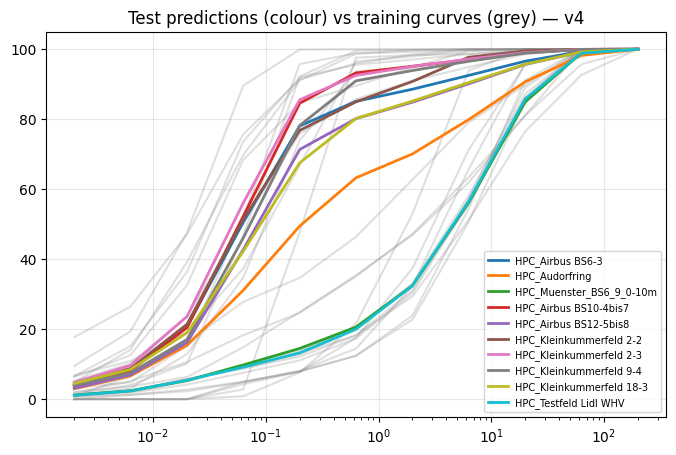

In [10]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 5))
for c in Ys: plt.plot(BINS, c, color="gray", alpha=.25)
for s, c in zip(S.sample_id, v): plt.plot(BINS, c, lw=2, label=s)
plt.xscale("log"); plt.grid(alpha=.3); plt.legend(fontsize=7)
plt.title("Test predictions (colour) vs training curves (grey) — v4")
plt.savefig(f"{OUT}/pred_curves.png", dpi=120); plt.show()

## 11. Appendix — the rejected "consistency MLP" experiment (kept for transparency)

A small 2-layer network (PCA input -> tanh hidden -> softmax -> cumsum), trained by
hand-derived backprop directly on the exact competition metric, with an added penalty that
pulls together its predictions for the SAME soil sample photographed on different cameras.
The idea: attack the diagnosed camera-confound directly, by training the network to ignore it.
Gradient verified against finite differences before use. Under honest leave-one-sample-out
CV it did not beat plain knn (see the top-of-file summary), so it is NOT part of the ensemble
above. Run this cell yourself if you want to explore tuning it further (more epochs, a
different hidden width, a larger consistency weight, more feature blocks).

In [11]:
def _softmax(z):
    e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def _mlp_forward(Z, params):
    W1, b1, W2, b2 = params
    H = np.tanh(Z @ W1 + b1); s = _softmax(H @ W2 + b2)
    return H, s, 100 * np.cumsum(s, 1)

def _mlp_loss_grad(Z, Y, sw, params, pair_idx, lam_cons, lam_l2):
    W1, b1, W2, b2 = params
    H, s, F = _mlp_forward(Z, params)
    d = F[:, :10] - Y[:, :10]
    gF = np.zeros_like(F); gF[:, :10] = np.sign(d) * W
    dm = 100 * np.cumsum(gF[:, ::-1], 1)[:, ::-1]
    g_logit = s * (dm - (s * dm).sum(1, keepdims=True)) * (sw / sw.sum())[:, None]
    loss = ((np.abs(d) * W).sum(1) * sw).sum() / sw.sum()
    if pair_idx is not None and len(pair_idx):
        i, j = pair_idx[:, 0], pair_idx[:, 1]; diff = s[i] - s[j]
        loss += lam_cons * np.mean((diff ** 2).sum(1))
        gi, gj = 2 * lam_cons * diff / len(pair_idx), -2 * lam_cons * diff / len(pair_idx)
        gs = np.zeros_like(s); np.add.at(gs, i, gi); np.add.at(gs, j, gj)
        g_logit = g_logit + s * (gs - (s * gs).sum(1, keepdims=True))
    gW2 = H.T @ g_logit + lam_l2 * W2; gb2 = g_logit.sum(0)
    gZpre = (g_logit @ W2.T) * (1 - H ** 2)
    return loss, [Z.T @ gZpre + lam_l2 * W1, gZpre.sum(0), gW2, gb2]

class ConsistentMLP(Base):
    """See the appendix note above: tried, gradient-verified, did not beat knn under honest CV."""
    def fit(self, X, Y, g, cam):
        Xs, sw = self._fit_scale(X), sample_weights(g)
        n, k, nh = len(Xs), self.kw.get("npc", 16), self.kw.get("nh", 8)
        lam_, U = np.linalg.eigh(Xs @ Xs.T)
        top = np.argsort(lam_)[::-1][:k]; lam_, U = np.maximum(lam_[top], 1e-9), U[:, top]
        self.Pj = Xs.T @ U / np.sqrt(lam_) / np.sqrt(lam_ / n)
        Z = Xs @ self.Pj
        pairs = [(a, b) for s in np.unique(g) for a in np.where((g == s) & (cam == "M"))[0][:3]
                 for b in np.where((g == s) & (cam == "S"))[0][:3]]
        pair_idx = np.array(pairs) if pairs else None
        self.runs = []
        for seed in range(self.kw.get("seeds", 3)):
            rng = np.random.default_rng(seed)
            W1 = rng.standard_normal((k, nh)) / np.sqrt(k); b1 = np.zeros(nh)
            W2 = rng.standard_normal((nh, 11)) / np.sqrt(nh)
            b2 = np.log(np.maximum(np.diff(np.concatenate([[0], np.average(Y, 0, sw)])), 1e-3) / 100)
            params = [W1, b1, W2, b2]; m = [np.zeros_like(p) for p in params]; v = [np.zeros_like(p) for p in params]
            epochs = self.kw.get("epochs", 300)
            for t in range(1, epochs + 1):
                _, grads = _mlp_loss_grad(Z, Y, sw, params, pair_idx, self.kw.get("lam_cons", 1.0), self.kw.get("lam_l2", 0.01))
                step = 0.05 * (0.5 * (1 + np.cos(np.pi * t / epochs)) + 0.02)
                for i, (p, gr) in enumerate(zip(params, grads)):
                    m[i] = 0.9 * m[i] + 0.1 * gr; v[i] = 0.999 * v[i] + 0.001 * gr ** 2
                    p -= step * (m[i] / (1 - 0.9 ** t)) / (np.sqrt(v[i] / (1 - 0.999 ** t)) + 1e-8)
            self.runs.append(params)
        return self
    def predict(self, X):
        Z = self._scale(X) @ self.Pj
        return np.mean([_mlp_forward(Z, p)[2] for p in self.runs], 0)

# Example: try it on the 'spec' feature set with LOSO CV (compare its printed EMD to the
# 'spec|knn|k=*' rows in the Top 20 table above)
_out = {}
for _s in sids:
    _trm = g_all != _s
    _m = ConsistentMLP(SETS["spec"]["spec"], npc=16, nh=8, lam_cons=1.0, epochs=300).fit(
        SETS["spec"]["Xtr"][_trm], Yrows[_trm], g_all[_trm], cam_all[_trm])
    _out[_s] = fix(np.median(_m.predict(SETS["spec"]["Xtr"][clean_rows[_s]]), 0))
print(f"ConsistentMLP on 'spec', LOSO EMD: {emd(Ys, np.stack([_out[s] for s in sids])).mean():.2f}  "
      f"(compare to the plain knn rows in the Top 20 table)")

ConsistentMLP on 'spec', LOSO EMD: 40.49  (compare to the plain knn rows in the Top 20 table)
